# Body Mass vs Maximum Longevity in Mammals

**Research question:** Do heavier mammal species live longer, and how strong is that association?

**Data:** `Datasets/anage_data.csv` — an extract of the AnAge database of animal longevity and
life-history traits. Mammals with body mass below 200,000 g are analysed (417 species).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

## 1. Load and filter the data

In [2]:
mydata = pd.read_csv("Datasets/anage_data.csv")
print("full extract:", mydata.shape)

data = mydata[(mydata["Class"] == "Mammalia") & (mydata["Body mass (g)"] < 200000)].copy()
print("mammals analysed:", data.shape)
data[["Common name", "Body mass (g)", "Maximum longevity (yrs)"]].head()

full extract: (4218, 30)
mammals analysed: (417, 30)


,Common name,Body mass (g),Maximum longevity (yrs)
1530,Lesser hedgehog tenrec,116.4,19.0
1531,Large-eared tenrec,6.9,NaN
1532,Streaked tenrec,116.4,2.7
1533,Dobson's shrew tenrec,44.6,5.6
1534,Talazac's shrew tenrec,44.0,5.8


## 2. Correlation between body mass and longevity

In [3]:
mass = data["Body mass (g)"]
longevity = data["Maximum longevity (yrs)"]

pearson_raw = mass.corr(longevity)
pearson_log = np.log10(mass).corr(longevity)
spearman = mass.corr(longevity, method="spearman")

print("Pearson r, raw body mass      : %.3f" % pearson_raw)
print("Pearson r, log10 body mass    : %.3f" % pearson_log)
print("Spearman rho, raw body mass   : %.3f" % spearman)
print("median body mass (g)          : %.1f" % mass.median())
print("median maximum longevity (yrs): %.1f" % longevity.median())

Pearson r, raw body mass      : 0.427
Pearson r, log10 body mass    : 0.594
Spearman rho, raw body mass   : 0.654
median body mass (g)          : 225.0
median maximum longevity (yrs): 12.0


## 3. Figure 1 — body mass against maximum longevity

Body mass spans five orders of magnitude, so the horizontal axis is on a log10 scale. The linear
association is stronger on that scale (r = 0.59 against r = 0.43 for the raw values), which is why the
figure is drawn this way.

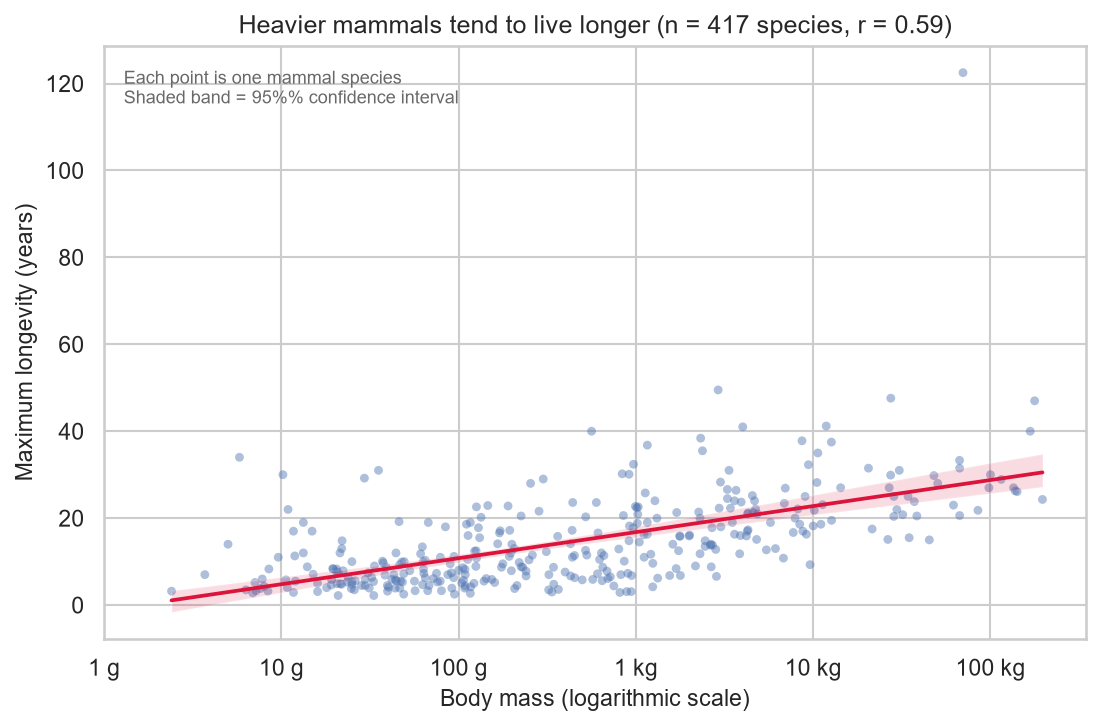

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5), dpi=150)

sns.regplot(
    x=np.log10(mass),
    y=longevity,
    ax=ax,
    scatter_kws={"s": 18, "alpha": 0.45, "edgecolor": "none"},
    line_kws={"color": "crimson", "lw": 1.8},
)

ax.set_xlabel("Body mass (logarithmic scale)", fontsize=11)
ax.set_ylabel("Maximum longevity (years)", fontsize=11)
ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["1 g", "10 g", "100 g", "1 kg", "10 kg", "100 kg"])
ax.set_title("Heavier mammals tend to live longer (n = %d species, r = %.2f)"
             % (len(data), pearson_log), fontsize=12)
ax.text(0.02, 0.96, "Each point is one mammal species\nShaded band = 95%% confidence interval",
        transform=ax.transAxes, va="top", fontsize=8.5, color="dimgray")

fig.tight_layout()
fig.savefig("visualizations/body_mass_vs_longevity.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Figure 2 — median longevity by body-mass class

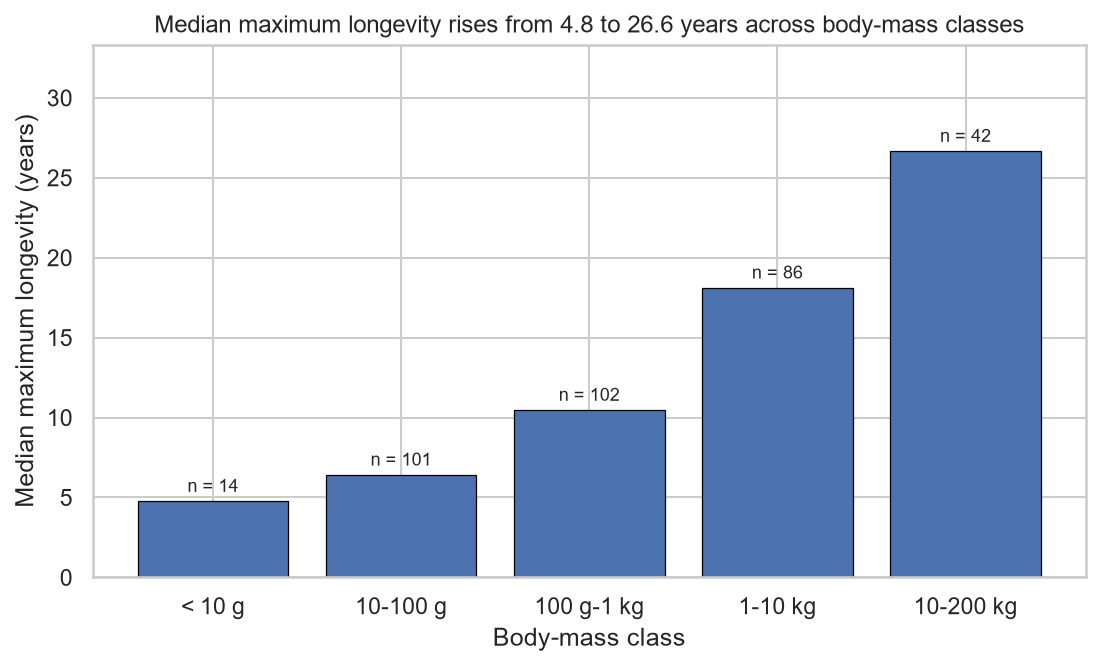

,median,count
mass_class,,
< 10 g,4.8,14
10-100 g,6.4,101
100 g-1 kg,10.4,102
1-10 kg,18.1,86
10-200 kg,26.6,42


In [5]:
bins = [0, 10, 100, 1000, 10000, 200000]
labels = ["< 10 g", "10-100 g", "100 g-1 kg", "1-10 kg", "10-200 kg"]
data["mass_class"] = pd.cut(mass, bins=bins, labels=labels)

summary = (data.groupby("mass_class", observed=True)["Maximum longevity (yrs)"]
               .agg(["median", "count"]))

fig, ax = plt.subplots(figsize=(7.5, 4.6), dpi=150)
bars = ax.bar(summary.index.astype(str), summary["median"],
              color="#4C72B0", edgecolor="black", linewidth=0.6)

for bar, n in zip(bars, summary["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6,
            "n = %d" % n, ha="center", fontsize=8.5)

ax.set_xlabel("Body-mass class")
ax.set_ylabel("Median maximum longevity (years)")
ax.set_title("Median maximum longevity rises from 4.8 to 26.6 years across body-mass classes",
             fontsize=11.5)
ax.set_ylim(0, summary["median"].max() * 1.25)

fig.tight_layout()
fig.savefig("visualizations/longevity_by_mass_class.png", dpi=150, bbox_inches="tight")
plt.show()

summary.round(1)

## 5. Findings

- Species in the heaviest class (10-200 kg) have a median maximum longevity of **26.6 years**, against
  **4.8 years** for species under 10 g — a monotone increase across all five classes.
- Body mass and longevity are positively associated: **r = 0.59** on a log10 mass scale
  (**rho = 0.65**), while raw mass gives a weaker **r = 0.43**.
- The association is moderate, not tight: longevity still ranges from 2 to over 100 years inside a
  single mass class, so body mass alone does not determine lifespan.

## 6. Limitation

This is an observational analysis of one curated database. Correlation does not imply causation, the
records differ in data quality and provenance, and the 200,000 g cut-off deliberately excludes the
largest mammals (for example elephants and whales), so the conclusions describe this sample rather than
all mammals.